<a href="https://colab.research.google.com/github/tluong1507/TrinhLuong_DTSC3020_Fall2026/blob/main/DTSC3020_Lesson9_Lecture_note_10252026_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<style>
.jp-RenderedHTMLCommon h1 { color: #0b6b3a; border-bottom: 2px solid #dcefe5; padding-bottom: 6px; }
.jp-RenderedHTMLCommon h2 { color: #0e5f43; margin-top: 28px; }
.jp-RenderedHTMLCommon h3 { color: #205b85; }
.callout { border-left: 7px solid #0b6b3a; background: #f3fbf5; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.warning { border-left: 7px solid #b45309; background: #fff8e6; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.activity { border-left: 7px solid #2563eb; background: #f2f6ff; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.checkpoint { border-left: 7px solid #7c3aed; background: #f8f5ff; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.quiz { border: 1px solid #d8e2ea; background: #fbfdff; padding: 14px 18px; margin: 16px 0; border-radius: 10px; }
.figcap { font-size: 0.9em; color: #52616b; margin-top: 6px; }
.figure { margin: 18px 0 24px 0; padding: 8px; background: #ffffff; border: 1px solid #d8e2ea; border-radius: 14px; }
.small { font-size: 0.92em; color: #52616b; }
</style>

# DTSC 3020: Introduction to Computation with Python
## Lesson 9: Arrays and Data Analysis Tools: array, NumPy, SciPy, and pandas

**Instructor:** Dr. Haihua Chen
**Department of Data Science, University of North Texas**

<div class="callout">
<b>Big idea:</b> Python lists are wonderful, but they were not designed for fast numerical work. Data scientists rely on a small family of libraries that build on one another: <b>array</b> → <b>NumPy</b> → <b>SciPy</b> → <b>pandas</b>. Today you will meet all four and finish with a small, complete data analysis.
</div>

## Lesson 9 Learning Objectives

By the end of this lesson, you should be able to:

1. Explain why Python lists are not ideal for large amounts of numeric data, and when the `array` module helps.
2. Create and modify `array.array` objects using type codes, and compare their memory use with lists.
3. Create NumPy arrays and describe their `shape`, `dtype`, and `ndim`; index and slice them, and explain **views** versus **copies**.
4. Use **vectorized** operations, **boolean masks**, aggregation with `axis`, and **broadcasting**.
5. Describe what SciPy adds to NumPy, and use `linalg`, `integrate`, `optimize`, and `stats` for small problems.
6. Create pandas `Series` and `DataFrame` objects and read and write CSV files.
7. Select, filter, and transform data with `loc`, `iloc`, boolean conditions, and new columns; find and handle **missing values**.
8. Summarize data with `groupby`, and combine tables with `concat` and `merge`.
9. Combine pandas, NumPy, and SciPy in one analysis, and **verify** the results (including AI-generated code) with asserts and small tests, as in Lesson 8.

# Part 0. Warm-Up and Setup

Imagine a teacher wants to add 5 bonus points to every exam score. With a Python list, what happens?

In [ ]:
scores = [88, 92, 79]

print(scores * 2)          # * means REPEAT for a list, not "multiply every element"

try:
    print(scores + 5)      # + means CONCATENATE two lists, not "add 5 to every element"
except TypeError as error:
    print("TypeError:", error)

curved = [s + 5 for s in scores]       # works, but we must write a loop (comprehension) ourselves
print(curved)

[88, 92, 79, 88, 92, 79]
TypeError: can only concatenate list (not "int") to list
[93, 97, 84]


<div class="checkpoint">
<b>Checkpoint:</b> The loop above is fine for 3 scores. How long would it take for <b>10 million</b> sensor readings? What if the data is a <b>table</b> with 20 columns, missing values, and several files to combine? Today's four tools solve exactly these problems.
</div>

## Setup: Import the Libraries

Google Colab and Anaconda already include NumPy, SciPy, pandas, and matplotlib. If an import fails on your own computer, run `%pip install numpy scipy pandas matplotlib` in a cell and restart the kernel.

By convention we **import with short aliases**: `np` for NumPy and `pd` for pandas. You will see these two names in almost every data science program.

In [ ]:
import sys
import time
from pathlib import Path

import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("lesson9_data")
DATA_DIR.mkdir(exist_ok=True)

print("Python  :", sys.version.split()[0])
print("NumPy   :", np.__version__)
print("SciPy   :", scipy.__version__)
print("pandas  :", pd.__version__)

Python  : 3.9.21
NumPy   : 1.21.5
SciPy   : 1.7.3
pandas  : 1.4.2


<div class="figure">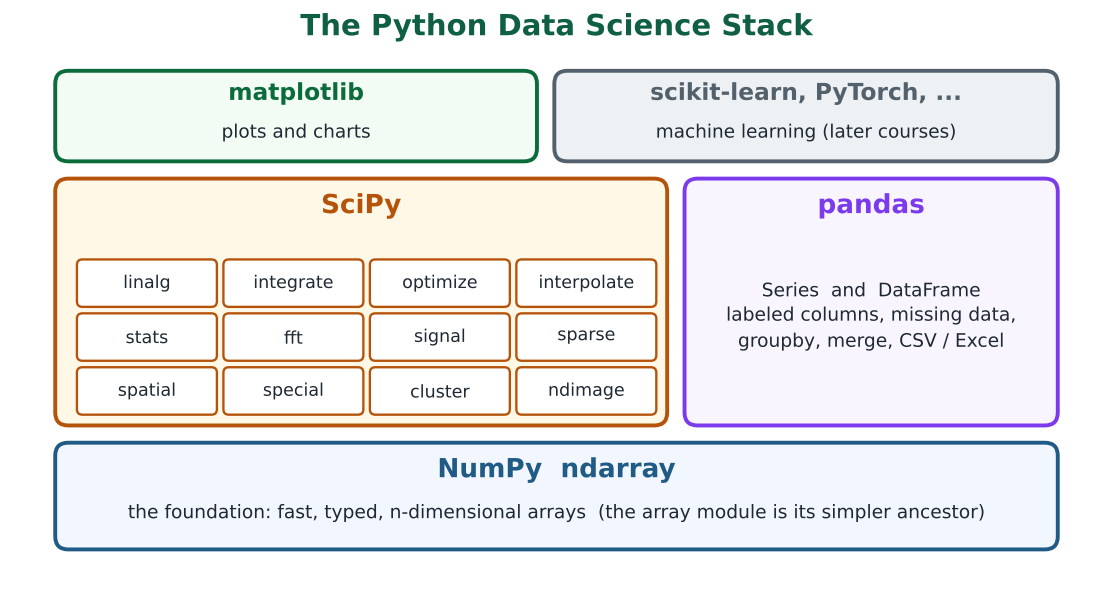<p class="figcap">Everything in today's lesson sits on top of the NumPy array.</p></div>

# Part 1. The `array` Module: Compact, Typed Arrays

**Reading:** [Python Array Module — DataFlair](https://data-flair.training/blogs/python-array-module/) | [array — Python Docs](https://docs.python.org/3/library/array.html)

Python has no built-in "array" type. The standard library offers the `array` module for one special case: a collection of numbers that are **all the same type**, stored **compactly**.

## 1.1 List vs. array: How Are They Stored?

<div class="figure">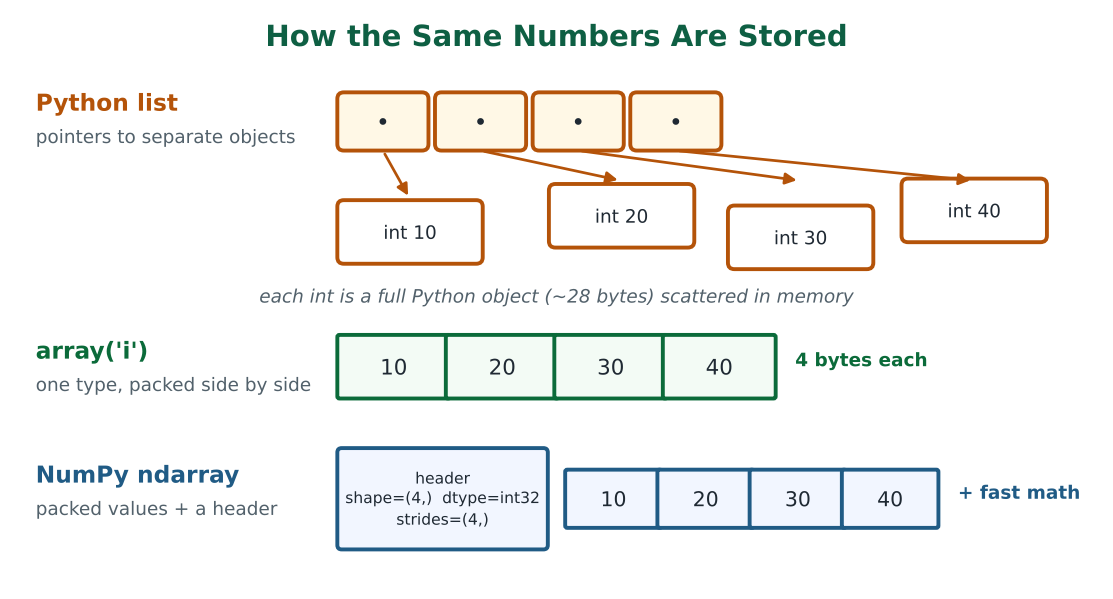</div>

| | Python `list` | `array.array` |
|---|---|---|
| Element types | **Anything**, mixed | **One** numeric type, chosen at creation |
| Storage | Pointers to separate Python objects | Packed raw values side by side |
| Memory per number | Large (pointer + a full object) | Small (for example 4 bytes for `'i'`) |
| Math on the whole array | No | No (neither is vectorized) |
| Dimensions | Nested lists | **One** dimension only |
| Needs an import | No | `from array import array` |

## 1.2 Type Codes

You tell Python which type to use with a **type code** (a single letter). Run the cell to see the size of each type **on your computer**:

| Code | C type | Python type | Typical use |
|---|---|---|---|
| `'b'` / `'B'` | signed / unsigned char | int | tiny integers (-128..127 / 0..255) |
| `'h'` / `'H'` | signed / unsigned short | int | small integers |
| `'i'` / `'I'` | signed / unsigned int | int | ordinary integers |
| `'l'` / `'L'` | signed / unsigned long | int | larger integers |
| `'q'` / `'Q'` | signed / unsigned long long | int | very large integers |
| `'f'` | float | float | decimals, 4 bytes (less precise) |
| `'d'` | double | float | decimals, 8 bytes (the same precision as a Python `float`) |

In [ ]:
from array import array

for code in "bBhHiIlLqQfd":
    print(f"type code {code!r:4} -> itemsize = {array(code).itemsize} byte(s)")

type code 'b'  -> itemsize = 1 byte(s)
type code 'B'  -> itemsize = 1 byte(s)
type code 'h'  -> itemsize = 2 byte(s)
type code 'H'  -> itemsize = 2 byte(s)
type code 'i'  -> itemsize = 4 byte(s)
type code 'I'  -> itemsize = 4 byte(s)
type code 'l'  -> itemsize = 8 byte(s)
type code 'L'  -> itemsize = 8 byte(s)
type code 'q'  -> itemsize = 8 byte(s)
type code 'Q'  -> itemsize = 8 byte(s)
type code 'f'  -> itemsize = 4 byte(s)
type code 'd'  -> itemsize = 8 byte(s)


## 1.3 Creating and Using an Array

`array(typecode, initializer)`: the initializer is usually a list. Arrays support **indexing, slicing, `len`, concatenation (`+`), repetition (`*`)**, and loops just like lists.

In [ ]:
a = array("i", [10, 20, 30, 40])

print("array     :", a)
print("typecode  :", a.typecode, "| itemsize:", a.itemsize, "bytes | length:", len(a))
print("a[1]      :", a[1])
print("a[1:3]    :", a[1:3])
print("a + a     :", a + a)          # concatenation: a NEW array with 8 items
print("a * 2     :", a * 2)          # repetition, NOT multiplication of each value

for value in a:
    print(value, end="  ")

array     : array('i', [10, 20, 30, 40])
typecode  : i | itemsize: 4 bytes | length: 4
a[1]      : 20
a[1:3]    : array('i', [20, 30])
a + a     : array('i', [10, 20, 30, 40, 10, 20, 30, 40])
a * 2     : array('i', [10, 20, 30, 40, 10, 20, 30, 40])
10  20  30  40  

## 1.4 Arrays Are Strictly Typed

An array **refuses** values of the wrong type or of a size that does not fit. This protects you from silent mistakes.

In [ ]:
numbers = array("i", [1, 2, 3])

try:
    numbers.append(3.5)             # a float cannot go into an integer array
except TypeError as error:
    print("TypeError:", error)

tiny = array("b", [100, 127])       # 'b' holds -128..127
try:
    tiny.append(200)
except OverflowError as error:
    print("OverflowError:", error)

decimals = array("d", [1, 2, 3])    # ints are converted to floats
print(decimals)

TypeError: integer argument expected, got float
OverflowError: signed char is greater than maximum
array('d', [1.0, 2.0, 3.0])


## 1.5 Array Methods

| Method | What it does |
|---|---|
| `append(x)` | Add `x` at the end |
| `extend(iterable)` | Add several items (must have the **same type**) |
| `fromlist(list)` | Append all items from a list |
| `insert(i, x)` | Insert `x` before position `i` |
| `pop(i)` | Remove and return the item at position `i` (default: last) |
| `remove(x)` | Remove the **first** occurrence of `x` |
| `index(x)` | Position of the first `x` |
| `count(x)` | How many times `x` appears |
| `reverse()` | Reverse **in place** |
| `tolist()` | Convert to an ordinary list |
| `tobytes()` | The raw bytes (used for binary files) |
| `buffer_info()` | `(memory address, number of items)` |

<div class="warning">
<b>Old tutorials:</b> <code>tostring()</code> was removed in Python 3.9. Use <code>tobytes()</code>. The <code>'u'</code> (Unicode) type code is deprecated; use ordinary strings instead.
</div>

In [ ]:
arr = array("i", [1, 3, 2, 4, 3, 5])
print("start          :", arr)

arr.append(7);          print("append(7)      :", arr)
arr.extend([9, 8]);     print("extend([9, 8]) :", arr)
arr.insert(2, 99);      print("insert(2, 99)  :", arr)
print("pop(2) returned:", arr.pop(2), "->", arr)
arr.remove(3);          print("remove(3)      :", arr)         # only the FIRST 3 is removed
print("index(4)       :", arr.index(4), "| count(3):", arr.count(3))
arr.reverse();          print("reverse()      :", arr)
print("tolist()       :", arr.tolist(), type(arr.tolist()))
print("tobytes length :", len(arr.tobytes()), "bytes for", len(arr), "items")

start          : array('i', [1, 3, 2, 4, 3, 5])
append(7)      : array('i', [1, 3, 2, 4, 3, 5, 7])
extend([9, 8]) : array('i', [1, 3, 2, 4, 3, 5, 7, 9, 8])
insert(2, 99)  : array('i', [1, 3, 99, 2, 4, 3, 5, 7, 9, 8])
pop(2) returned: 99 -> array('i', [1, 3, 2, 4, 3, 5, 7, 9, 8])
remove(3)      : array('i', [1, 2, 4, 3, 5, 7, 9, 8])
index(4)       : 2 | count(3): 1
reverse()      : array('i', [8, 9, 7, 5, 3, 4, 2, 1])
tolist()       : [8, 9, 7, 5, 3, 4, 2, 1] <class 'list'>
tobytes length : 32 bytes for 8 items


## 1.6 Why Bother? Memory

For a million integers, let's compare the memory used by a list (the list **plus** all the int objects it points to) with an array.

In [ ]:
n = 1_000_000
as_list = list(range(n))
as_array = array("i", range(n))

list_bytes = sys.getsizeof(as_list) + sum(sys.getsizeof(x) for x in as_list)
array_bytes = sys.getsizeof(as_array)

print(f"list : {list_bytes / 1e6:6.1f} MB")
print(f"array: {array_bytes / 1e6:6.1f} MB")
print(f"the list uses about {list_bytes / array_bytes:.0f} times more memory")

list :   36.0 MB
array:    4.1 MB
the list uses about 9 times more memory


## 1.7 The Limits of `array`

The `array` module saves memory, but it does **not** give us fast math, 2-D tables, or statistics: `a * 2` repeats, `a + a` concatenates, and there is no `a.mean()`. We need something stronger.

<div class="callout">
<b>Bridge to NumPy:</b> NumPy keeps the idea of a compact, typed array and adds <b>vectorized math</b>, <b>many dimensions</b>, and hundreds of fast functions.
</div>

<div class="activity">
<b>Quick Activity (2 min):</b> Create an <code>array('d')</code> of five Celsius temperatures. Convert them to Fahrenheit (<code>F = C * 9/5 + 32</code>) into a <b>new</b> array. How many lines did the loop need? Keep that number in mind for Part 2.
</div>

In [ ]:
# Activity: Celsius -> Fahrenheit with the array module
celsius = array("d", [-5.0, 0.0, 18.5, 25.0, 37.0])

# TODO: build `fahrenheit` (an array('d')) using a loop

<details>
<summary><b>Click to reveal one possible answer</b></summary>

```python
fahrenheit = array("d")
for c in celsius:
    fahrenheit.append(c * 9 / 5 + 32)
print(fahrenheit)       # array('d', [23.0, 32.0, 65.3, 77.0, 98.6])
```

A loop of 3 lines. With NumPy it will be one expression: `celsius * 9 / 5 + 32`.

</details>

# Part 2. NumPy: The Foundation of Scientific Python

**Reading:** [Python NumPy Tutorial — DataFlair](https://data-flair.training/blogs/python-numpy-tutorial/) | [NumPy quickstart](https://numpy.org/doc/stable/user/quickstart.html)

NumPy's core object is the **`ndarray`** (n-dimensional array): a grid of values that are **all the same type**, stored in one block of memory. Operations run in fast compiled code, so we can write `a * 2` instead of a loop.

## 2.1 Creating Arrays

In [ ]:
a = np.array([1, 2, 3, 4])                    # from a list
m = np.array([[1, 2, 3], [4, 5, 6]])           # from a list of lists -> 2-D

print("a =", a, "| type:", type(a))
print("m =\n", m)

print("zeros       :", np.zeros(3))
print("ones (2x2)  :\n", np.ones((2, 2)))
print("full        :", np.full(3, 7))
print("arange      :", np.arange(0, 10, 2))      # like range(), but returns an array
print("linspace    :", np.linspace(0, 1, 5))     # 5 evenly spaced values, both ends included
print("eye (ident.):\n", np.eye(3))

rng = np.random.default_rng(seed=42)             # modern, reproducible random numbers
print("random ints :", rng.integers(0, 100, size=5))
print("random norm :", rng.normal(loc=0, scale=1, size=3).round(3))

a = [1 2 3 4] | type: <class 'numpy.ndarray'>
m =
 [[1 2 3]
 [4 5 6]]
zeros       : [0. 0. 0.]
ones (2x2)  :
 [[1. 1.]
 [1. 1.]]
full        : [7 7 7]
arange      : [0 2 4 6 8]
linspace    : [0.   0.25 0.5  0.75 1.  ]
eye (ident.):
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
random ints : [ 8 77 65 43 43]
random norm : [ 0.941 -1.951 -1.302]


## 2.2 Attributes: shape, ndim, size, dtype

| Attribute | Meaning |
|---|---|
| `shape` | Tuple with the length of each dimension, e.g. `(2, 3)` = 2 rows, 3 columns |
| `ndim` | Number of dimensions |
| `size` | Total number of elements |
| `dtype` | Type of every element (`int64`, `float64`, `bool`, ...) |
| `itemsize` | Bytes per element |

In [ ]:
m = np.array([[1, 2, 3], [4, 5, 6]])
print("shape   :", m.shape)
print("ndim    :", m.ndim)
print("size    :", m.size)
print("dtype   :", m.dtype)
print("itemsize:", m.itemsize, "bytes ->", m.nbytes, "bytes in total")

# dtype is decided automatically, or you can choose it
print(np.array([1, 2, 3]).dtype, np.array([1, 2.5, 3]).dtype, np.array([1, 2, 3], dtype=np.float32).dtype)
print(np.array([1, 2, 3]).astype(float))            # astype returns a converted COPY

shape   : (2, 3)
ndim    : 2
size    : 6
dtype   : int64
itemsize: 8 bytes -> 48 bytes in total
int64 float64 float32
[1. 2. 3.]


<div class="warning">
<b>Fixed-size integers can overflow silently.</b> Unlike a Python <code>int</code>, a NumPy <code>int8</code> wraps around without any error. This is why choosing a <code>dtype</code> matters.
</div>

In [ ]:
small = np.array([127], dtype=np.int8)
print(small + 1)            # wraps around to -128 (the 'b' array from Part 1 raised an error instead)

[-128]


## 2.3 Reshaping

`reshape` changes the shape **without changing the data**. Use `-1` to let NumPy work out one dimension.

In [ ]:
x = np.arange(12)
print(x)
print(x.reshape(3, 4))
print(x.reshape(2, -1).shape, "<- -1 means 'figure it out'")
print(x.reshape(3, 4).T.shape, "<- .T transposes")
print(x.reshape(3, 4).flatten())

[ 0  1  2  3  4  5  6  7  8  9 10 11]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2, 6) <- -1 means 'figure it out'
(4, 3) <- .T transposes
[ 0  1  2  3  4  5  6  7  8  9 10 11]


## 2.4 Indexing and Slicing

Indexing works like lists, with one extra trick for 2-D arrays: `m[row, column]`. Slices are `start:stop:step` for each axis.

```
m[1, 2]      one element            m[:, 0]     the whole first column
m[0]         the first row          m[0:2, 1:3] a rectangular block
```

In [ ]:
m = np.arange(1, 13).reshape(3, 4)
print(m)
print("m[1, 2]     :", m[1, 2])
print("m[0]        :", m[0])
print("m[:, 0]     :", m[:, 0])
print("m[0:2, 1:3] :\n", m[0:2, 1:3])
print("m[-1, -1]   :", m[-1, -1])

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
m[1, 2]     : 7
m[0]        : [1 2 3 4]
m[:, 0]     : [1 5 9]
m[0:2, 1:3] :
 [[2 3]
 [6 7]]
m[-1, -1]   : 12


### Views vs. Copies (a common source of bugs)

A **slice** of a NumPy array is a **view**: it looks at the *same memory*. Changing the slice changes the original! (Python list slices make copies; NumPy does not.) Use `.copy()` when you need independence.

In [ ]:
original = np.array([10, 20, 30, 40, 50])

view = original[1:4]
view[0] = 999
print("original after changing the view:", original)         # original changed!

safe = original[1:4].copy()
safe[0] = -1
print("original after changing the copy:", original)         # unchanged
print("shares memory?", np.shares_memory(original, view), np.shares_memory(original, safe))

original after changing the view: [ 10 999  30  40  50]
original after changing the copy: [ 10 999  30  40  50]
shares memory? True False


## 2.5 Boolean Masks and Fancy Indexing

A comparison on an array gives a **boolean array** (a *mask*). Using the mask as an index keeps only the `True` positions. This replaces most of the `if` + `for` loops you wrote before.

In [ ]:
scores = np.array([55, 82, 91, 67, 74, 98, 45])

mask = scores >= 70
print("mask          :", mask)
print("scores >= 70  :", scores[mask])
print("count passing :", mask.sum(), "(True counts as 1)")
print("70..90        :", scores[(scores >= 70) & (scores <= 90)])      # use & | ~ (not and/or/not)
print("fancy index   :", scores[[0, 2, 5]])                              # pick positions by list

curved = scores.copy()
curved[curved < 60] = 60                                                  # assign through a mask
print("floor of 60   :", curved)
print("np.where      :", np.where(scores >= 60, "pass", "fail"))

mask          : [False  True  True False  True  True False]
scores >= 70  : [82 91 74 98]
count passing : 4 (True counts as 1)
70..90        : [82 74]
fancy index   : [55 91 98]
floor of 60   : [60 82 91 67 74 98 60]
np.where      : ['fail' 'pass' 'pass' 'pass' 'pass' 'pass' 'fail']


<div class="warning">
<b>Remember:</b> combine conditions with <code>&amp;</code>, <code>|</code>, <code>~</code> and put <b>parentheses</b> around each condition. Python's <code>and</code> / <code>or</code> raise an error on arrays.
</div>

## 2.6 Vectorization: Math on Whole Arrays

Operators work **element by element**, with no loop. This is called **vectorization**. It is shorter *and* much faster.

In [ ]:
celsius = np.array([-5.0, 0.0, 18.5, 25.0, 37.0])
print("Fahrenheit:", celsius * 9 / 5 + 32)          # compare with the loop in Part 1

a = np.array([1, 2, 3])
b = np.array([10, 20, 30])
print("a + b :", a + b, "| a * b :", a * b, "| a ** 2 :", a ** 2)
print("sqrt  :", np.sqrt(a).round(3), "| exp:", np.exp(a).round(2))

Fahrenheit: [23.  32.  65.3 77.  98.6]
a + b : [11 22 33] | a * b : [10 40 90] | a ** 2 : [1 4 9]
sqrt  : [1.    1.414 1.732] | exp: [ 2.72  7.39 20.09]


Speed test: sum of squares of 2 million numbers, loop vs. vectorized.

In [ ]:
data = np.arange(2_000_000, dtype=np.float64)

start = time.perf_counter()
total_loop = 0.0
for value in data.tolist():
    total_loop += value * value
t_loop = time.perf_counter() - start

start = time.perf_counter()
total_vec = np.sum(data * data)
t_vec = time.perf_counter() - start

print(f"loop       : {t_loop:.3f} s")
print(f"vectorized : {t_vec:.4f} s  (about {t_loop / max(t_vec, 1e-9):.0f}x faster)")
print("same answer?", np.isclose(total_loop, total_vec))

loop       : 0.272 s
vectorized : 0.0025 s  (about 109x faster)
same answer? True


## 2.7 Aggregations and the `axis` Argument

`sum`, `mean`, `min`, `max`, `std`, `argmax`, ... can summarize the whole array, or work along an **axis**:

- `axis=0`: collapse the **rows**, giving one result **per column**
- `axis=1`: collapse the **columns**, giving one result **per row**

<div class="figure">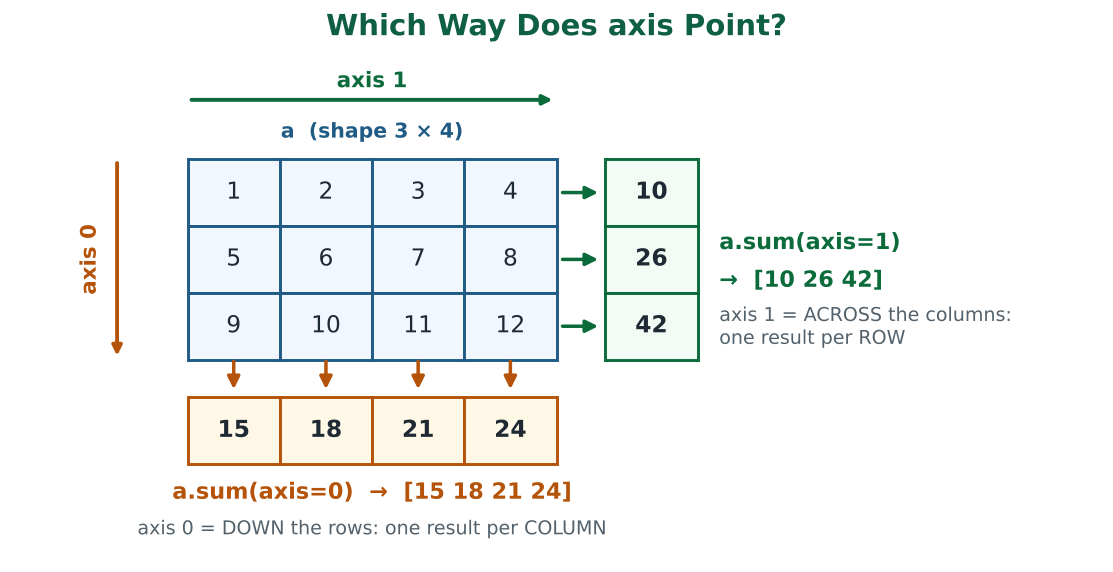</div>

In [ ]:
m = np.arange(1, 13).reshape(3, 4)
print(m)
print("whole array  :", m.sum(), m.mean(), m.max())
print("axis=0 (cols):", m.sum(axis=0))
print("axis=1 (rows):", m.sum(axis=1))
print("mean per col :", m.mean(axis=0))
print("argmax (flat):", m.argmax(), "| std:", m.std().round(3))
print("sorted       :", np.sort(np.array([3, 1, 2])), "| cumsum:", np.cumsum([1, 2, 3, 4]))

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
whole array  : 78 6.5 12
axis=0 (cols): [15 18 21 24]
axis=1 (rows): [10 26 42]
mean per col : [5. 6. 7. 8.]
argmax (flat): 11 | std: 3.452
sorted       : [1 2 3] | cumsum: [ 1  3  6 10]


## 2.8 Broadcasting

What if the shapes differ? NumPy **stretches** the smaller array across the larger one, provided the shapes are compatible (compare shapes from the right: each pair must be equal or one of them must be 1). No data is actually copied.

<div class="figure">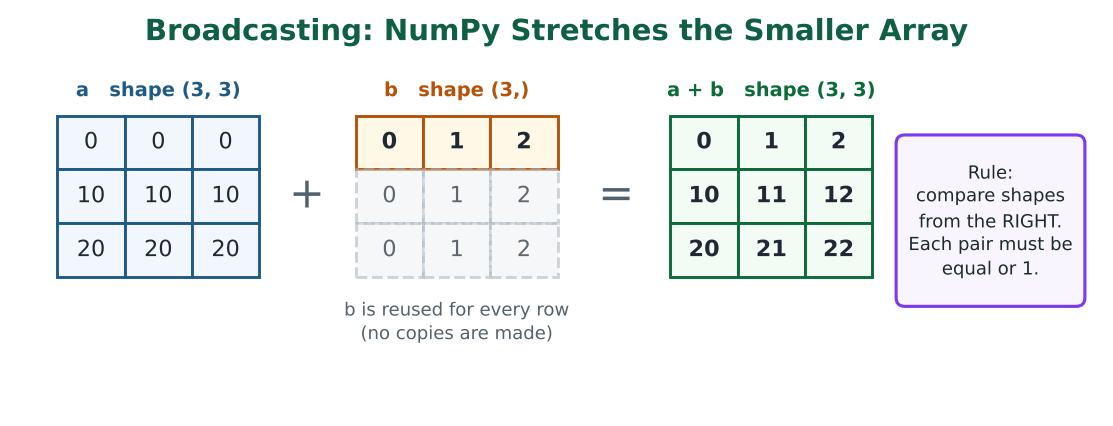</div>

In [ ]:
grid = np.array([[1, 2, 3],
                 [4, 5, 6],
                 [7, 8, 9]])
row = np.array([10, 20, 30])

print(grid + row)                 # row is added to EVERY row of grid
print(grid * 2)                   # a scalar is the simplest broadcast

# Real use: standardize each column (z-score) in one line
z = (grid - grid.mean(axis=0)) / grid.std(axis=0)
print(z.round(2))

try:
    grid + np.array([1, 2])       # shapes (3,3) and (2,) are not compatible
except ValueError as error:
    print("ValueError:", error)

[[11 22 33]
 [14 25 36]
 [17 28 39]]
[[ 2  4  6]
 [ 8 10 12]
 [14 16 18]]
[[-1.22 -1.22 -1.22]
 [ 0.    0.    0.  ]
 [ 1.22  1.22  1.22]]
ValueError: operands could not be broadcast together with shapes (3,3) (2,) 


<div class="activity">
<b>Activity 2 (5 min): Grade Curve with NumPy.</b>
Given the scores below: (1) add a curve of 5 points but cap every score at 100; (2) print the mean and standard deviation; (3) print how many students are <b>above the mean</b>; (4) print the highest score and the <b>position</b> where it appears.
</div>

In [ ]:
exam = np.array([62, 88, 95, 71, 54, 99, 80, 67])

# TODO 1: curved = ...
# TODO 2: mean and std of curved
# TODO 3: how many above the mean
# TODO 4: max score and its position

<details>
<summary><b>Click to reveal one possible answer</b></summary>

```python
curved = np.minimum(exam + 5, 100)
print(curved)                                  # [ 67  93 100  76  59 100  85  72]
print(curved.mean(), curved.std().round(2))
print((curved > curved.mean()).sum())          # 4
print(curved.max(), curved.argmax())           # 100 2  (first occurrence)
```

</details>

## 2.9 Take-Home: Linear Algebra and Handy Functions

The matrix product uses `@` (not `*`, which is element-wise).

In [ ]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[0, 1], [1, 0]])
print("A * B (element-wise):\n", A * B)
print("A @ B (matrix product):\n", A @ B)
print("transpose:\n", A.T)
print("inverse:\n", np.linalg.inv(A).round(2))
print("A @ inv(A):\n", (A @ np.linalg.inv(A)).round(10))

A * B (element-wise):
 [[0 2]
 [3 0]]
A @ B (matrix product):
 [[2 1]
 [4 3]]
transpose:
 [[1 3]
 [2 4]]
inverse:
 [[-2.   1. ]
 [ 1.5 -0.5]]
A @ inv(A):
 [[1. 0.]
 [0. 1.]]


In [ ]:
v = np.array([3, 1, 2, 3, 3, 1])
print("unique + counts:", np.unique(v, return_counts=True))
print("concatenate    :", np.concatenate([v[:2], v[-2:]]))
print("vstack         :\n", np.vstack([[1, 2], [3, 4]]))
print("clip           :", np.clip(v, 2, 3))
print("isnan          :", np.isnan(np.array([1.0, np.nan, 3.0])))
print("nanmean        :", np.nanmean(np.array([1.0, np.nan, 3.0])))

unique + counts: (array([1, 2, 3]), array([2, 1, 3]))
concatenate    : [3 1 3 1]
vstack         :
 [[1 2]
 [3 4]]
clip           : [3 2 2 3 3 2]
isnan          : [False  True False]
nanmean        : 2.0


<div class="callout">
<b>Testing numeric code (link to Lesson 8):</b> Floating-point results should not be compared with <code>==</code>. Use <code>np.isclose</code>/<code>np.allclose</code> or <code>np.testing.assert_allclose</code>.
</div>

In [ ]:
print(0.1 + 0.2 == 0.3, "<- float equality is unreliable")
print(np.isclose(0.1 + 0.2, 0.3))
np.testing.assert_allclose(celsius * 9 / 5 + 32, [23.0, 32.0, 65.3, 77.0, 98.6])
print("assert_allclose passed")

False <- float equality is unreliable
True
assert_allclose passed


# Part 3. SciPy: Scientific Algorithms

**Reading:** [Python SciPy Tutorial — DataFlair](https://data-flair.training/blogs/scipy-tutorial/) | [SciPy docs](https://docs.scipy.org/doc/scipy/)

NumPy stores and manipulates arrays. **SciPy** builds on it with ready-made algorithms. Each area lives in a **subpackage** that you import separately.

| Subpackage | What it offers | Example use |
|---|---|---|
| `scipy.linalg` | Linear algebra | Solve systems of equations |
| `scipy.integrate` | Integration, ODEs | Area under a curve |
| `scipy.optimize` | Minimization, curve fitting | Find the best parameters |
| `scipy.stats` | Distributions and tests | p-values, correlations |
| `scipy.interpolate` | Interpolation | Fill in between measurements |
| `scipy.fft` | Fourier transforms | Find frequencies in a signal |
| `scipy.special`, `scipy.constants` | Special functions, constants | `factorial`, speed of light |

<div class="warning">
<b>Old tutorials:</b> <code>scipy.weave</code> no longer exists, <code>scipy.fftpack</code> is legacy (use <code>scipy.fft</code>), and <code>interp1d</code> is legacy (use <code>CubicSpline</code> or <code>np.interp</code>). The examples below use the current API.
</div>

## 3.1 Linear Algebra: `scipy.linalg`

Solve the system: 2x + 3y = 7 and 3x + 4y = 10.

In [ ]:
from scipy import linalg

A = np.array([[2, 3],
              [3, 4]])
b = np.array([7, 10])

solution = linalg.solve(A, b)
print("x, y =", solution)
print("check A @ solution:", A @ solution)

M = np.array([[8, 2], [1, 4]])
print("det =", linalg.det(M))
print("inverse =\n", linalg.inv(M).round(3))
assert np.allclose(A @ solution, b)

x, y = [2. 1.]
check A @ solution: [ 7. 10.]
det = 30.0
inverse =
 [[ 0.133 -0.067]
 [-0.033  0.267]]


## 3.2 Integration: `scipy.integrate`

`quad` computes a definite integral numerically and returns `(value, estimated_error)`. The area under x² from 0 to 4 is 4³/3 = 21.333...

In [ ]:
from scipy import integrate

value, error = integrate.quad(lambda x: x ** 2, 0, 4)
print(f"integral of x^2 on [0, 4] = {value:.4f}  (error estimate {error:.1e})")
assert np.isclose(value, 64 / 3)

# The Gaussian bell curve integrates to sqrt(pi) over the whole line
value, _ = integrate.quad(lambda x: np.exp(-x ** 2), -np.inf, np.inf)
print("Gaussian integral:", round(value, 6), "vs sqrt(pi) =", round(np.sqrt(np.pi), 6))

integral of x^2 on [0, 4] = 21.3333  (error estimate 2.4e-13)
Gaussian integral: 1.772454 vs sqrt(pi) = 1.772454


## 3.3 Optimization: `scipy.optimize`

**Minimize** a function: find the input that makes the output smallest. Here f(x) = (x − 3)² + 2 has its minimum at x = 3.

In [ ]:
from scipy import optimize

def f(x):
    return (x[0] - 3) ** 2 + 2

result = optimize.minimize(f, x0=[0.0])
print("best x    :", result.x.round(4))
print("min value :", round(result.fun, 4))
print("converged :", result.success)

best x    : [3.]
min value : 2.0
converged : True


**Curve fitting** finds the parameters of a model that best match noisy data. This is a first taste of machine learning.

fitted slope = 2.49, intercept = 0.89  (true: 2.5 and 1.0)


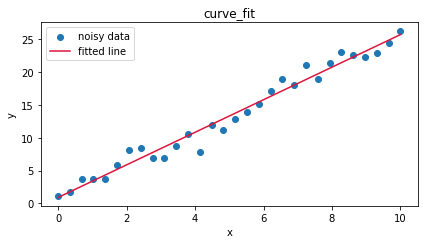

In [ ]:
rng = np.random.default_rng(0)
x = np.linspace(0, 10, 30)
y = 2.5 * x + 1.0 + rng.normal(0, 1.5, size=x.size)       # true line: slope 2.5, intercept 1.0

def line(x, slope, intercept):
    return slope * x + intercept

params, _ = optimize.curve_fit(line, x, y)
print(f"fitted slope = {params[0]:.2f}, intercept = {params[1]:.2f}  (true: 2.5 and 1.0)")

plt.figure(figsize=(6, 3.5))
plt.scatter(x, y, label="noisy data")
plt.plot(x, line(x, *params), color="crimson", label="fitted line")
plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("curve_fit"); plt.tight_layout(); plt.show()

## 3.4 Statistics: `scipy.stats`

`stats` has more than 100 probability distributions. Each has `pdf`/`pmf`, `cdf` (probability of being **less than or equal**), `ppf` (the inverse of the cdf) and `rvs` (random samples).

Suppose exam scores follow a normal distribution with mean 75 and standard deviation 10.

In [ ]:
from scipy import stats

exam = stats.norm(loc=75, scale=10)
print("P(score <= 85)    :", round(exam.cdf(85), 4))
print("P(score > 90)     :", round(1 - exam.cdf(90), 4))       # about 6.7% of students
print("top 10% start at  :", round(exam.ppf(0.90), 2))
print("ppf of 2.3 (invalid probability):", stats.norm.ppf(2.3))   # nan, not an error

print("z-scores:", stats.zscore([60, 70, 80, 90]).round(2))

P(score <= 85)    : 0.8413
P(score > 90)     : 0.0668
top 10% start at  : 87.82
ppf of 2.3 (invalid probability): nan
z-scores: [-1.34 -0.45  0.45  1.34]


### Comparing two groups: the t-test, and correlation

Do students who attended the review session score higher? `ttest_ind` returns a **p-value**: the probability of seeing a difference this large *if there were really no difference*. A small p-value (commonly below 0.05) is evidence of a real difference.

In [ ]:
attended = [88, 92, 85, 79, 94, 90, 87]
skipped  = [72, 80, 65, 78, 70, 83, 69]

t_stat, p_value = stats.ttest_ind(attended, skipped)
print(f"t = {t_stat:.2f}, p = {p_value:.4f}")
print("Significant at 0.05?", p_value < 0.05)

hours = [1, 2, 3, 4, 5, 6, 7, 8]
grade = [52, 58, 61, 70, 74, 79, 85, 90]
r, p = stats.pearsonr(hours, grade)
print(f"Pearson r = {r:.3f} (p = {p:.1e})")

fit = stats.linregress(hours, grade)
print(f"each extra hour adds about {fit.slope:.1f} points; R^2 = {fit.rvalue ** 2:.3f}")

t = 4.50, p = 0.0007
Significant at 0.05? True
Pearson r = 0.997 (p = 5.0e-08)
each extra hour adds about 5.5 points; R^2 = 0.995


<div class="warning">
<b>Statistics caution:</b> A tiny p-value shows an effect is unlikely to be pure chance. It does <b>not</b> prove the cause, and it says nothing about whether the effect is large or important. Correlation is not causation.
</div>

<div class="activity">
<b>Activity 3 (4 min): Use SciPy.</b> (1) Solve x + y = 10 and x − y = 2 with <code>linalg.solve</code>. (2) Integrate sin(x) from 0 to π with <code>quad</code> (the answer should be 2). (3) With a normal distribution (mean 100, sd 15), find P(score between 85 and 115).
</div>

In [ ]:
# TODO 1: linalg.solve
# TODO 2: integrate.quad of np.sin on [0, np.pi]
# TODO 3: stats.norm(100, 15).cdf(115) - ...cdf(85)

<details>
<summary><b>Click to reveal one possible answer</b></summary>

```python
print(linalg.solve([[1, 1], [1, -1]], [10, 2]))              # [6. 4.]
print(integrate.quad(np.sin, 0, np.pi)[0])                   # 2.0
d = stats.norm(100, 15)
print(round(d.cdf(115) - d.cdf(85), 4))                      # 0.6827 (the "68%" rule)
```

</details>

## 3.5 Take-Home: Interpolation and Fourier Transform

**Interpolation** estimates values *between* measurements. **FFT** finds which frequencies are present in a signal.

In [ ]:
from scipy.interpolate import CubicSpline

known_x = np.array([0, 1, 2, 3, 4])
known_y = np.array([0, 1, 8, 27, 64])            # y = x^3
spline = CubicSpline(known_x, known_y)
print("estimate at 2.5:", spline(2.5).round(3), "| true value:", 2.5 ** 3)
print("np.interp (straight lines) at 2.5:", np.interp(2.5, known_x, known_y))

estimate at 2.5: 15.625 | true value: 15.625
np.interp (straight lines) at 2.5: 17.5


In [ ]:
from scipy.fft import rfft, rfftfreq

fs = 200                                           # samples per second
t = np.arange(0, 1, 1 / fs)
signal = np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 20 * t)     # 5 Hz + 20 Hz

spectrum = np.abs(rfft(signal))
freqs = rfftfreq(signal.size, 1 / fs)
top_two = freqs[np.argsort(spectrum)[-2:]]
print("strongest frequencies (Hz):", sorted(top_two.tolist()))

# Part 4. pandas: Tables for Data Analysis

**Reading:** [Python Pandas Tutorial — DataFlair](https://data-flair.training/blogs/pandas-tutorial/) | [10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html)

pandas gives Python a **spreadsheet-like table** with named columns, mixed types, missing values, and powerful grouping. It is built on NumPy: every column is (essentially) a NumPy array.

| Structure | Dimensions | Think of it as |
|---|---|---|
| `Series` | 1-D | One column, with an index (labels) |
| `DataFrame` | 2-D | A whole table: columns are Series sharing one index |

<div class="warning">
<b>Old tutorials:</b> <code>Panel</code> (3-D) was removed from pandas. Also avoid <code>inplace=True</code> and chained assignment such as <code>df[df.x &gt; 1]['y'] = 0</code>; write <code>df = df.method(...)</code> and <code>df.loc[mask, 'y'] = 0</code> instead.
</div>

## 4.1 Series

In [ ]:
s = pd.Series([88, 92, 79], index=["Ana", "Ben", "Cho"], name="score")
print(s)
print("\nBen:", s["Ben"], "| first:", s.iloc[0], "| mean:", s.mean())
print("\nscore + 5:\n", s + 5)                  # vectorized, like NumPy; the index is kept
print("\nvalues as NumPy:", s.to_numpy())

Ana    88
Ben    92
Cho    79
Name: score, dtype: int64

Ben: 92 | first: 88 | mean: 86.33333333333333

score + 5:
 Ana    93
Ben    97
Cho    84
Name: score, dtype: int64

values as NumPy: [88 92 79]


## 4.2 DataFrame: Creating and Inspecting

The most common way to create one is from a **dictionary of columns**, or by reading a file (next section).

<div class="figure">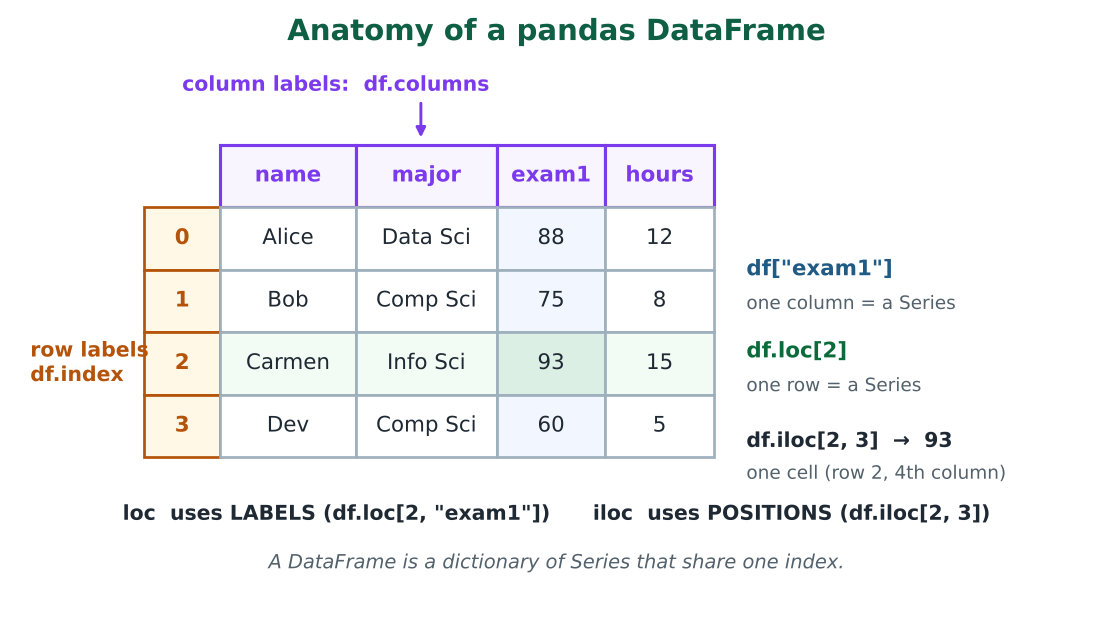</div>

In [ ]:
df = pd.DataFrame({
    "name":   ["Ana", "Ben", "Cho", "Dev", "Eli", "Fay"],
    "major":  ["DS", "CS", "DS", "IS", "CS", "DS"],
    "hours":  [6.5, 3.0, 8.0, 5.5, 2.0, 7.0],
    "score":  [91, 70, 96, 84, 62, 93],
})
print(df)
print("\nshape:", df.shape)
print(df.dtypes)

  name major  hours  score
0  Ana    DS    6.5     91
1  Ben    CS    3.0     70
2  Cho    DS    8.0     96
3  Dev    IS    5.5     84
4  Eli    CS    2.0     62
5  Fay    DS    7.0     93

shape: (6, 4)
name      object
major     object
hours    float64
score      int64
dtype: object


In [ ]:
print(df.head(3))
print()
df.info()
print()
print(df.describe().round(2))            # summary statistics of numeric columns

  name major  hours  score
0  Ana    DS    6.5     91
1  Ben    CS    3.0     70
2  Cho    DS    8.0     96

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   name    6 non-null      object 
 1   major   6 non-null      object 
 2   hours   6 non-null      float64
 3   score   6 non-null      int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 320.0+ bytes

       hours  score
count   6.00   6.00
mean    5.33  82.67
std     2.36  13.74
min     2.00  62.00
25%     3.62  73.50
50%     6.00  87.50
75%     6.88  92.50
max     8.00  96.00


## 4.3 Reading and Writing CSV Files

You wrote text files by hand in Lesson 8. `read_csv` does the parsing for you. We first create a CSV file, then read it back.

<div class="warning">
<b>Pitfall:</b> <code>to_csv</code> also writes the row index as an extra first column. Reading that file back creates a column called <code>Unnamed: 0</code>. Always use <code>index=False</code>.
</div>

In [ ]:
csv_path = DATA_DIR / "students.csv"
df.to_csv(csv_path, index=False)
print(csv_path.read_text())

students = pd.read_csv(csv_path)
print(students.equals(df))               # True: a perfect round trip

name,major,hours,score
Ana,DS,6.5,91
Ben,CS,3.0,70
Cho,DS,8.0,96
Dev,IS,5.5,84
Eli,CS,2.0,62
Fay,DS,7.0,93

True


## 4.4 Selecting Data

| You want | Use | Example |
|---|---|---|
| One column (a Series) | `df["col"]` | `df["score"]` |
| Several columns (a DataFrame) | `df[["a", "b"]]` | `df[["name", "score"]]` |
| Rows/columns by **label** | `df.loc[rows, cols]` | `df.loc[0:2, "name"]` (end **included**) |
| Rows/columns by **position** | `df.iloc[rows, cols]` | `df.iloc[0:2, 0]` (end **excluded**) |
| Rows meeting a condition | boolean mask | `df[df["score"] > 90]` |

In [ ]:
print(df["score"].tolist())
print(df[["name", "score"]].head(2))
print("\nloc  rows 0..2, name:", df.loc[0:2, "name"].tolist())      # label slice: includes 2
print("iloc rows 0..1, col0:", df.iloc[0:2, 0].tolist())             # position slice: excludes 2
print("\nscore > 90:\n", df[df["score"] > 90])
print("\nDS with 7+ hours:\n", df[(df["major"] == "DS") & (df["hours"] >= 7)])
print("\nCS or IS:\n", df[df["major"].isin(["CS", "IS"])])
print("\nquery:\n", df.query("score >= 90 and hours < 8"))

[91, 70, 96, 84, 62, 93]
  name  score
0  Ana     91
1  Ben     70

loc  rows 0..2, name: ['Ana', 'Ben', 'Cho']
iloc rows 0..1, col0: ['Ana', 'Ben']

score > 90:
   name major  hours  score
0  Ana    DS    6.5     91
2  Cho    DS    8.0     96
5  Fay    DS    7.0     93

DS with 7+ hours:
   name major  hours  score
2  Cho    DS    8.0     96
5  Fay    DS    7.0     93

CS or IS:
   name major  hours  score
1  Ben    CS    3.0     70
3  Dev    IS    5.5     84
4  Eli    CS    2.0     62

query:
   name major  hours  score
0  Ana    DS    6.5     91
5  Fay    DS    7.0     93


## 4.5 New Columns, Sorting, Renaming

New columns are computed for the **whole column at once**, exactly like NumPy vectorization. `pd.cut` turns numbers into categories.

In [ ]:
df["passed"] = df["score"] >= 70
df["points_per_hour"] = (df["score"] / df["hours"]).round(1)
df["grade"] = pd.cut(df["score"], bins=[0, 60, 70, 80, 90, 101],
                     labels=["F", "D", "C", "B", "A"], right=False)

print(df.sort_values("score", ascending=False))
print()
print(df.rename(columns={"hours": "study_hours"}).drop(columns=["points_per_hour"]).head(2))
print()
print(df["major"].value_counts())

  name major  hours  score  passed  points_per_hour grade
2  Cho    DS    8.0     96    True             12.0     A
5  Fay    DS    7.0     93    True             13.3     A
0  Ana    DS    6.5     91    True             14.0     A
3  Dev    IS    5.5     84    True             15.3     B
1  Ben    CS    3.0     70    True             23.3     C
4  Eli    CS    2.0     62   False             31.0     D

  name major  study_hours  score  passed grade
0  Ana    DS          6.5     91    True     A
1  Ben    CS          3.0     70    True     C

DS    3
CS    2
IS    1
Name: major, dtype: int64


## 4.6 Missing Data

Real data is rarely complete. pandas marks missing values as `NaN` (not a number). Always **find** them first, then decide: drop, fill, or leave.

In [ ]:
messy = pd.DataFrame({
    "name":  ["Ana", "Ben", "Cho", "Dev"],
    "quiz1": [90, np.nan, 75, 88],
    "quiz2": [85, 70, np.nan, np.nan],
})
print(messy)
print("\nmissing per column:\n", messy.isna().sum())
print("\ndrop rows with any NaN:\n", messy.dropna())
print("\nfill NaN with column mean:\n", messy.fillna(messy[["quiz1", "quiz2"]].mean()).round(1))
print("\nmean skips NaN by default:", messy["quiz1"].mean())

  name  quiz1  quiz2
0  Ana   90.0   85.0
1  Ben    NaN   70.0
2  Cho   75.0    NaN
3  Dev   88.0    NaN

missing per column:
 name     0
quiz1    1
quiz2    2
dtype: int64

drop rows with any NaN:
   name  quiz1  quiz2
0  Ana   90.0   85.0

fill NaN with column mean:
   name  quiz1  quiz2
0  Ana   90.0   85.0
1  Ben   84.3   70.0
2  Cho   75.0   77.5
3  Dev   88.0   77.5

mean skips NaN by default: 84.33333333333333


<div class="callout">
<b>Think before you fill:</b> Filling with the mean keeps the table complete but hides the fact that data was missing. Dropping rows loses information. There is no universal answer, so <b>document your choice</b>.
</div>

## 4.7 groupby: Split, Apply, Combine

`groupby` splits the rows into groups, computes something for each group, and combines the answers into a new table.

<div class="figure">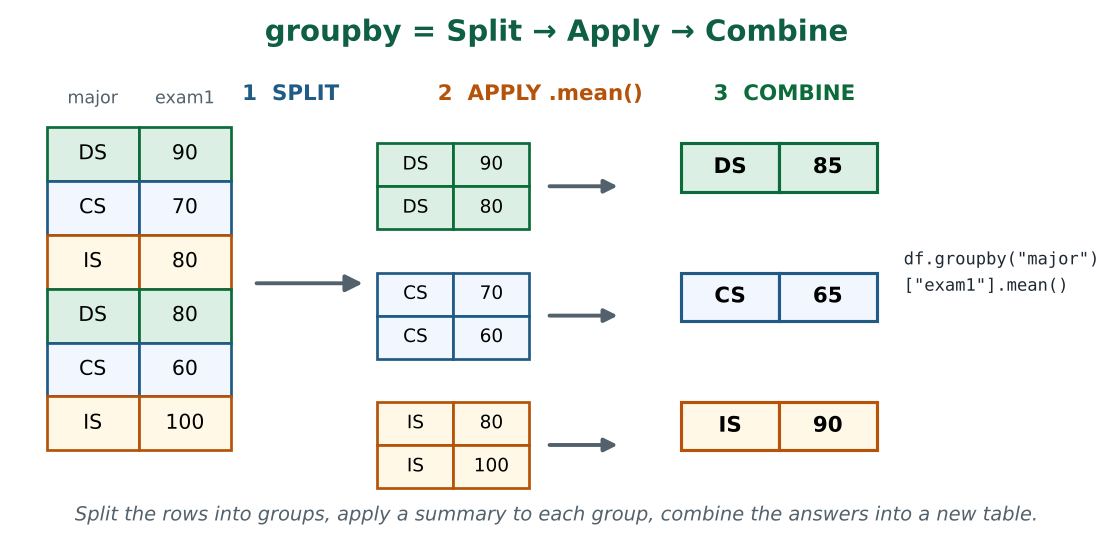</div>

In [ ]:
by_major = df.groupby("major")["score"].mean()
print(by_major.round(1))

summary = df.groupby("major").agg(
    students=("name", "count"),
    avg_score=("score", "mean"),
    best_score=("score", "max"),
    avg_hours=("hours", "mean"),
).round(1)
print()
print(summary)
print()
print(pd.crosstab(df["major"], df["passed"]))

major
CS    66.0
DS    93.3
IS    84.0
Name: score, dtype: float64

       students  avg_score  best_score  avg_hours
major                                            
CS            2       66.0          70        2.5
DS            3       93.3          96        7.2
IS            1       84.0          84        5.5

passed  False  True
major              
CS          1     1
DS          0     3
IS          0     1


## 4.8 Combining Tables: concat and merge

- `pd.concat`: stack tables on top of each other (same columns).
- `pd.merge`: join two tables on a shared **key column** (like a database join).

In [ ]:
extra = pd.DataFrame({"name": ["Gus"], "major": ["IS"], "hours": [4.0], "score": [77]})
stacked = pd.concat([df[["name", "major", "hours", "score"]], extra], ignore_index=True)
print(stacked.tail(2))

advisors = pd.DataFrame({"major": ["DS", "CS", "IS"], "advisor": ["Dr. Chen", "Dr. Lee", "Dr. Smith"]})
with_advisor = stacked.merge(advisors, on="major", how="left")
print()
print(with_advisor)

  name major  hours  score
5  Fay    DS    7.0     93
6  Gus    IS    4.0     77

  name major  hours  score    advisor
0  Ana    DS    6.5     91   Dr. Chen
1  Ben    CS    3.0     70    Dr. Lee
2  Cho    DS    8.0     96   Dr. Chen
3  Dev    IS    5.5     84  Dr. Smith
4  Eli    CS    2.0     62    Dr. Lee
5  Fay    DS    7.0     93   Dr. Chen
6  Gus    IS    4.0     77  Dr. Smith


<div class="activity">
<b>Activity 4 (6 min): Explore a table.</b>
Using <code>stacked</code> (7 students): (1) show only students with a score below 80; (2) add a column <code>efficiency = score / hours</code>; (3) find the <b>major with the highest average efficiency</b>.
</div>

In [ ]:
# TODO 1: low scorers
# TODO 2: efficiency column on a copy of stacked
# TODO 3: best major by mean efficiency (hint: groupby + idxmax)

<details>
<summary><b>Click to reveal one possible answer</b></summary>

```python
print(stacked[stacked["score"] < 80])
table = stacked.assign(efficiency=stacked["score"] / stacked["hours"])
print(table.groupby("major")["efficiency"].mean().idxmax())
```

</details>

# Part 5. Mini Project: Does Study Time Predict Exam Scores?

We combine **pandas** (table and groupby), **NumPy** (arrays and masks), **SciPy** (regression and test) and **matplotlib** (plot). The data is synthetic, generated with a fixed seed so everyone gets the same numbers.

## 5.1 Build and Save the Data

In [ ]:
rng = np.random.default_rng(2026)
n = 60
project = pd.DataFrame({
    "student_id": np.arange(1, n + 1),
    "major": rng.choice(["DS", "CS", "IS"], size=n),
    "hours": rng.uniform(0, 10, size=n).round(1),
})
project["score"] = (50 + 4.5 * project["hours"] + rng.normal(0, 6, size=n)).clip(0, 100).round(0)
project.loc[rng.choice(n, size=4, replace=False), "score"] = np.nan        # 4 missing scores

project.to_csv(DATA_DIR / "project.csv", index=False)
project = pd.read_csv(DATA_DIR / "project.csv")
print(project.head())
print("missing scores:", project["score"].isna().sum())

   student_id major  hours  score
0           1    IS    2.1   62.0
1           2    DS    8.7   91.0
2           3    DS    8.0   79.0
3           4    CS    6.1    NaN
4           5    CS    3.5   65.0
missing scores: 4


## 5.2 Clean, Summarize, Test, Plot

rows kept: 56 of 60
        n  mean_score  mean_hours
major                            
CS     24        73.8         5.4
DS     18        75.5         5.8
IS     14        67.4         4.0

slope = 4.68 points per hour, intercept = 48.4, r = 0.88, p = 5.5e-19
5+ hours: 82.6 vs under 5 hours: 62.1 (p = 2.9e-10)


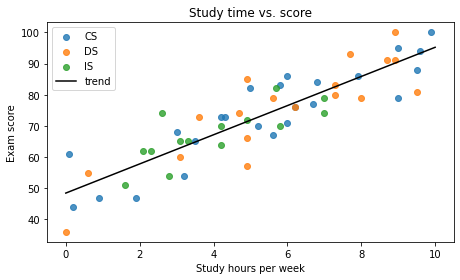

In [ ]:
clean = project.dropna(subset=["score"])                       # decision: drop rows without a score
print("rows kept:", len(clean), "of", len(project))

print(clean.groupby("major").agg(n=("score", "count"), mean_score=("score", "mean"),
                                 mean_hours=("hours", "mean")).round(1))

fit = stats.linregress(clean["hours"], clean["score"])
print(f"\nslope = {fit.slope:.2f} points per hour, intercept = {fit.intercept:.1f}, "
      f"r = {fit.rvalue:.2f}, p = {fit.pvalue:.1e}")

heavy = clean[clean["hours"] >= 5]["score"]
light = clean[clean["hours"] < 5]["score"]
t, p = stats.ttest_ind(heavy, light)
print(f"5+ hours: {heavy.mean():.1f} vs under 5 hours: {light.mean():.1f} (p = {p:.1e})")

plt.figure(figsize=(6.5, 4))
for name, g in clean.groupby("major"):
    plt.scatter(g["hours"], g["score"], label=name, alpha=0.8)
xs = np.array([0, 10])
plt.plot(xs, fit.intercept + fit.slope * xs, color="black", label="trend")
plt.xlabel("Study hours per week"); plt.ylabel("Exam score"); plt.title("Study time vs. score")
plt.legend(); plt.tight_layout(); plt.show()

## 5.3 Verify the Analysis

Good analysts **test their own results**, and never trust AI-generated code blindly. Small asserts catch many mistakes.

In [ ]:
assert clean["score"].notna().all(), "no missing scores should remain"
assert clean["score"].between(0, 100).all(), "scores must be 0-100"
assert fit.slope > 0, "more study time should not lower the score in this data"
assert np.isclose(fit.slope, np.polyfit(clean["hours"], clean["score"], 1)[0]), "two methods must agree"
print("All checks passed")

All checks passed


<div class="warning">
<b>Ask an AI, then verify.</b> Suppose an AI assistant answers "average score by major" with <code>df.groupby('major').mean()</code>. Does it work on a table that contains the text column <code>name</code>? In recent pandas it raises a <code>TypeError</code>; in some older versions it silently dropped the column. Run the code, read the error, and fix it with <code>df.groupby('major')['score'].mean()</code>. <b>You</b> are responsible for the result.
</div>

<div class="activity">
<b>Extension (take-home):</b> Redo the analysis keeping the missing scores but <b>filling</b> them with each major's mean (hint: <code>groupby(...)['score'].transform('mean')</code>). Do the slope and p-value change much? What does that tell you about the missing-data decision?
</div>

# Part 6. Wrap-Up

## 6.1 Cheat Sheet

| Task | array | NumPy | pandas |
|---|---|---|---|
| Create | `array('i', [1, 2])` | `np.array([1, 2])` | `pd.DataFrame({...})`, `pd.read_csv(path)` |
| Size | `len(a)` | `a.shape`, `a.size` | `df.shape`, `df.info()` |
| Math on all values | loop needed | `a * 2` | `df["x"] * 2` |
| Filter | loop needed | `a[a > 3]` | `df[df["x"] > 3]` |
| Summarize | no | `a.mean(axis=0)` | `df.describe()`, `df.groupby("k").agg(...)` |
| Missing values | no | `np.isnan`, `np.nanmean` | `isna`, `dropna`, `fillna` |
| Test results | n/a | `np.allclose`, `assert_allclose` | `assert`, `Series.between`, `equals` |

## 6.2 Which Tool Do I Need?

- **Memory-light list of one number type, no math** → `array`
- **Fast math on numbers, matrices, images** → NumPy
- **Statistics, optimization, integration, solving equations** → SciPy
- **Labeled tables, CSV files, mixed types, missing data, groupby** → pandas

## 6.3 Key Takeaways

1. Python lists are flexible but slow and large for numbers; `array` is compact; NumPy is **compact and vectorized**.
2. NumPy slices are **views**; use `.copy()` when needed. Use `&`, `|`, `~` for masks.
3. `axis=0` summarizes **down the rows** (one result per column); `axis=1` one result per row.
4. SciPy provides tested algorithms; import the subpackage you need (`from scipy import stats`).
5. In pandas: `loc` is by label, `iloc` by position; avoid `inplace` and chained assignment; check missing data before analysing.
6. Statistics supports decisions but does not prove causes. **Test and verify** your results.

## 6.4 Quiz (self-check)

<div class="quiz">
<p><b>Question 1. What does <code>array('i', [1, 2, 3]) * 2</code> return?</b></p>

- A. <code>array('i', [2, 4, 6])</code>
- B. <code>array('i', [1, 2, 3, 1, 2, 3])</code>
- C. A TypeError
- D. <code>[2, 4, 6]</code>

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. <code>array('i', [1, 2, 3, 1, 2, 3])</code>

<br><br>

<b>Explanation:</b> Like lists, <code>*</code> on an <code>array.array</code> means repetition. Element-wise math is what NumPy adds.
</details>
</div>

<div class="quiz">
<p><b>Question 2. <code>b = a[1:3]</code> for a NumPy array <code>a</code>. You then set <code>b[0] = 0</code>. What happens to <code>a</code>?</b></p>

- A. Nothing, slices are copies
- B. <code>a[1]</code> also becomes 0
- C. An error is raised
- D. <code>a</code> is deleted

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. <code>a[1]</code> also becomes 0

<br><br>

<b>Explanation:</b> A NumPy slice is a view on the same memory. Use <code>a[1:3].copy()</code> for an independent array.
</details>
</div>

<div class="quiz">
<p><b>Question 3. For <code>m</code> of shape (3, 4), what is the shape of <code>m.sum(axis=0)</code>?</b></p>

- A. (3,)
- B. (4,)
- C. (3, 4)
- D. A single number

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. (4,)

<br><br>

<b>Explanation:</b> axis=0 collapses the rows, leaving one value for each of the 4 columns.
</details>
</div>

<div class="quiz">
<p><b>Question 4. What is the shape of <code>np.ones((3, 3)) + np.array([1, 2, 3])</code>?</b></p>

- A. Error
- B. (3,)
- C. (3, 3)
- D. (9,)

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. (3, 3)

<br><br>

<b>Explanation:</b> The shape (3,) row is broadcast across the 3 rows of the 3x3 matrix.
</details>
</div>

<div class="quiz">
<p><b>Question 5. Which expression selects scores that are at least 60 <b>and</b> below 90?</b></p>

- A. <code>a[(a &gt;= 60) and (a &lt; 90)]</code>
- B. <code>a[(a &gt;= 60) &amp; (a &lt; 90)]</code>
- C. <code>a[60 &lt;= a &lt; 90]</code>
- D. <code>a[a &gt;= 60, a &lt; 90]</code>

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. <code>a[(a &gt;= 60) &amp; (a &lt; 90)]</code>

<br><br>

<b>Explanation:</b> Use <code>&amp;</code> with parentheses. <code>and</code> and chained comparisons raise an error for arrays.
</details>
</div>

<div class="quiz">
<p><b>Question 6. Which SciPy subpackage would you use to compute a p-value?</b></p>

- A. <code>scipy.linalg</code>
- B. <code>scipy.integrate</code>
- C. <code>scipy.stats</code>
- D. <code>scipy.fft</code>

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. <code>scipy.stats</code>

<br><br>

<b>Explanation:</b> <code>scipy.stats</code> has distributions and statistical tests such as <code>ttest_ind</code>.
</details>
</div>

<div class="quiz">
<p><b>Question 7. <code>df.loc[0:2, 'name']</code> and <code>df.iloc[0:2, 0]</code> return how many rows?</b></p>

- A. 3 and 2
- B. 2 and 2
- C. 3 and 3
- D. 2 and 3

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> A. 3 and 2

<br><br>

<b>Explanation:</b> <code>loc</code> slices by label and <b>includes</b> the end; <code>iloc</code> slices by position and <b>excludes</b> it.
</details>
</div>

<div class="quiz">
<p><b>Question 8. You save a DataFrame with <code>df.to_csv('f.csv')</code> and read it back. What extra column appears?</b></p>

- A. <code>index</code>
- B. <code>Unnamed: 0</code>
- C. <code>id</code>
- D. None

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. <code>Unnamed: 0</code>

<br><br>

<b>Explanation:</b> The row index was written as a column with no name. Use <code>to_csv('f.csv', index=False)</code>.
</details>
</div>

<div class="quiz">
<p><b>Question 9. What does <code>df.groupby('major')['score'].mean()</code> produce?</b></p>

- A. One overall mean
- B. One mean per major
- C. The mean of each row
- D. A copy of df

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. One mean per major

<br><br>

<b>Explanation:</b> Split by major, apply mean to each group, combine into a Series indexed by major.
</details>
</div>

<div class="quiz">
<p><b>Question 10. You compare <code>0.1 + 0.2</code> with <code>0.3</code> in a test. What should you use?</b></p>

- A. <code>==</code>
- B. <code>is</code>
- C. <code>np.isclose</code> or <code>pytest.approx</code>
- D. <code>int()</code>

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. <code>np.isclose</code> or <code>pytest.approx</code>

<br><br>

<b>Explanation:</b> Floating-point numbers carry tiny rounding errors, so compare within a tolerance.
</details>
</div>

## 6.5 Exit Ticket

Answer in one or two sentences each:

1. What is the **one** idea from today that you could use in your own project?
2. Which part is still unclear: `array`, NumPy `axis`/broadcasting, SciPy, or pandas `loc`/`groupby`?
3. Name one way you would **check** that an analysis result is correct.

## 6.6 Practice Problems (Take-Home)

1. **NumPy:** Create a 5×5 array of the numbers 1 to 25. Print the sum of the diagonal (`np.trace`), the second column, and all values divisible by 3.
2. **Broadcasting:** Standardize each *row* of a 4×3 array to mean 0 (hint: `keepdims=True`).
3. **SciPy:** Fit `y = a * exp(b * x)` to your own data with `curve_fit`. Report `a` and `b`.
4. **pandas:** Read `lesson9_data/project.csv`; compute the median score per major and list the three students with the highest `score / hours`.
5. **Testing:** Write three asserts for a function that returns the mean of a pandas column, including one for a column with a missing value.

## Sources and Credits

- Python Array Module, SciPy Tutorial, NumPy Tutorial, Pandas Tutorial: DataFlair Training (data-flair.training), used as the starting outline. Examples were rewritten and outdated APIs (`Panel`, `weave`, `fftpack`, `tostring`) replaced with current ones.
- Official documentation: [array](https://docs.python.org/3/library/array.html), [NumPy](https://numpy.org/doc/stable/), [SciPy](https://docs.scipy.org/doc/scipy/), [pandas](https://pandas.pydata.org/docs/).
- Format follows the Lesson 1 and Lesson 8 notebooks.

*Code was written for NumPy 1.26+/2.x, SciPy 1.11+, and pandas 2.x/3.x.*